#Modelo de clasificación para Moda viva
## Fase 1: conexión con la BD 



In [8]:
## Fase 1: Importar librerias 
import pandas as pd  #manejo de bases de datos 
import numpy as np #operaciones logicas
import matplotlib.pyplot as plt #graficos
import seaborn as sns #graficos estadisticos 
import mysql.connector
from getpass import getpass


In [10]:
# 1) Crear la conexión
cnx = mysql.connector.connect(
    host="localhost",       # cambialo si no es localhost
    port=3306,              # cambialo si tu puerto es otro
    user="root",            # tu usuario
    password="5579855Macama.", 
    database="reto_modaviva"  # el schema que aparece en Workbench
)

In [ ]:
#cargar bd ventas
query_ventas= "select * from reto_modaviva.ventas"
df_ventas= pd.read_sql(query_ventas, cnx)
df_ventas.head(15)

C:\Users\Camila\AppData\Local\Temp\ipykernel_18964\672304979.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_ventas= pd.read_sql(query, cnx)


,id_venta,fecha,id_cliente,id_producto,id_tienda,cantidad,precio_venta,descuento
0,1,2024-01-14,183,60,3,2,255000,0.1
1,2,2024-01-17,183,17,5,1,171000,0.1
2,3,2024-01-24,239,58,5,1,257000,0.0
3,4,2024-01-27,70,35,1,2,147000,0.0
4,5,2024-01-29,283,49,3,1,263000,0.1
5,6,2024-01-31,366,37,1,1,81000,0.1
6,7,2024-02-11,18,57,6,1,378000,0.3
7,8,2024-02-11,153,8,5,1,116000,0.0
8,9,2024-02-11,229,17,1,2,171000,0.0
9,10,2024-02-11,244,55,2,2,360000,0.0


In [14]:
#cargar el resto de las tablas de datos desde sql
query_tiendas= "select * from reto_modaviva.tiendas"
query_productos= "select * from reto_modaviva.productos"
query_inventario= "select * from reto_modaviva.inventario"
query_clientes= "select * from reto_modaviva.clientes"

df_tiendas= pd.read_sql(query_tiendas, cnx)
df_productos= pd.read_sql(query_productos, cnx)
df_inventario= pd.read_sql(query_inventario, cnx)
df_clientes= pd.read_sql(query_clientes, cnx)



C:\Users\Camila\AppData\Local\Temp\ipykernel_18964\3855608112.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_tiendas= pd.read_sql(query_tiendas, cnx)
C:\Users\Camila\AppData\Local\Temp\ipykernel_18964\3855608112.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_productos= pd.read_sql(query_productos, cnx)
C:\Users\Camila\AppData\Local\Temp\ipykernel_18964\3855608112.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_inventario= pd.read_sql(query_inventario, cnx)
C:\Users\Camila\AppData\Local\Temp\ipykernel_

# Fase 2: exploración de las bases de datos

In [41]:
#como saber el nombre de las columnas de la base? 
df_clientes.columns

Index(['id_cliente', 'nombre_cliente', 'ciudad', 'fecha_registro',
       'canal_preferido', 'antiguedad'],
      dtype='str')

In [42]:
df_clientes["fecha_registro"] = pd.to_datetime(df_clientes["fecha_registro"])
df_tiendas["fecha_apertura"] = pd.to_datetime(df_tiendas["fecha_apertura"])
df_inventario["fecha_corte"] = pd.to_datetime(df_inventario["fecha_corte"])
df_ventas["fecha"] = pd.to_datetime(df_ventas["fecha"])

In [28]:
df_tiendas.head()

,id_tienda,nombre_tienda,ciudad,tipo,fecha_apertura
0,1,Medellin Centro,Medellin,fisica,2019-03-15
1,2,Bogota Norte,Bogota,fisica,2020-06-01
2,3,Cali Sur,Cali,fisica,2021-02-10
3,4,Barranquilla Plaza,Barranquilla,fisica,2022-08-20
4,5,Medellin Poblado,Medellin,fisica,2023-05-05


In [29]:
df_clientes.head()

,id_cliente,nombre_cliente,ciudad,fecha_registro,canal_preferido,antiguedad
0,1,Paula Arango,Bogota,2024-07-24,online,antiguo
1,2,Gabriela Zapata,Bucaramanga,2025-04-07,tienda,nuevo
2,3,Manuela Gomez,Bucaramanga,2024-08-23,tienda,antiguo
3,4,Camila Vargas,Medellin,2024-02-02,online,antiguo
4,5,Andrea Ospina,Pereira,2025-05-12,tienda,nuevo


In [30]:
df_productos.head()

,id_producto,nombre_producto,categoria,subcategoria,precio,costo,temporada
0,1,Blusa Manga larga 01,Blusas,Manga larga,60000,25000,Otono-Invierno
1,2,Blusa Manga larga 02,Blusas,Manga larga,77000,35000,Todo el ano
2,3,Blusa Manga larga 03,Blusas,Manga larga,58000,29000,Todo el ano
3,4,Blusa Manga corta 01,Blusas,Manga corta,56000,28000,Primavera-Verano
4,5,Blusa Manga corta 02,Blusas,Manga corta,49000,21000,Primavera-Verano


In [31]:
df_inventario.head()

,id_producto,id_tienda,stock_actual,stock_minimo,fecha_corte,estado
0,1,1,22,10,2025-12-15,ok
1,1,2,23,8,2025-12-15,ok
2,1,3,33,12,2025-12-15,ok
3,1,4,34,12,2025-12-15,ok
4,1,5,24,10,2025-12-15,ok


In [32]:
df_ventas.describe()

,id_venta,id_cliente,id_producto,id_tienda,cantidad,precio_venta,descuento
count,2419.000000,2419.000000,2419.000000,2419.000000,2419.000000,2419.000000,2419.000000
mean,1210.000000,199.563456,30.779661,3.302604,1.394378,154562.215792,0.068747
std,698.449473,114.887353,18.386976,1.825798,0.646862,98222.392002,0.091936
min,1.000000,1.000000,1.000000,1.000000,1.000000,27000.000000,0.000000
25%,605.500000,108.000000,14.000000,2.000000,1.000000,72000.000000,0.000000
50%,1210.000000,197.000000,30.000000,3.000000,1.000000,116000.000000,0.000000
75%,1814.500000,292.000000,48.000000,5.000000,2.000000,219000.000000,0.100000
max,2419.000000,400.000000,60.000000,6.000000,3.000000,378000.000000,0.300000


In [33]:
df_ventas.info()

<class 'pandas.DataFrame'>
RangeIndex: 2419 entries, 0 to 2418
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_venta      2419 non-null   int64  
 1   fecha         2419 non-null   str    
 2   id_cliente    2419 non-null   int64  
 3   id_producto   2419 non-null   int64  
 4   id_tienda     2419 non-null   int64  
 5   cantidad      2419 non-null   int64  
 6   precio_venta  2419 non-null   int64  
 7   descuento     2419 non-null   float64
dtypes: float64(1), int64(6), str(1)
memory usage: 151.3 KB


## Cruce de bases de datos 

In [ ]:
#union de dos bases de datos
df_vtas_pcto= df_ventas.merge(df_productos, on="id_producto", how="inner")
df_vtas_pcto.head()

,id_venta,fecha,id_cliente,id_producto,id_tienda,cantidad,precio_venta,descuento,nombre_producto,categoria,subcategoria,precio,costo,temporada
0,1,2024-01-14,183,60,3,2,255000,0.1,Chaqueta Cuero sintetico 03,Chaquetas,Cuero sintetico,255000,138000,Primavera-Verano
1,2,2024-01-17,183,17,5,1,171000,0.1,Jean Recto 02,Jeans,Recto,171000,92000,Otono-Invierno
2,3,2024-01-24,239,58,5,1,257000,0.0,Chaqueta Cuero sintetico 01,Chaquetas,Cuero sintetico,257000,135000,Todo el ano
3,4,2024-01-27,70,35,1,2,147000,0.0,Vestido Coctel 02,Vestidos,Coctel,147000,66000,Todo el ano
4,5,2024-01-29,283,49,3,1,263000,0.1,Chaqueta Jean 01,Chaquetas,Jean,263000,142000,Todo el ano


In [37]:
#unir 3 bases de datos
df_full=(df_vtas_pcto.merge(df_clientes,on="id_cliente",how="inner")
         .merge(df_tiendas,on="id_tienda",how="inner"))
df_full.head()

,id_venta,fecha,id_cliente,id_producto,id_tienda,cantidad,precio_venta,descuento,nombre_producto,categoria,...,temporada,nombre_cliente,ciudad_x,fecha_registro,canal_preferido,antiguedad,nombre_tienda,ciudad_y,tipo,fecha_apertura
0,1,2024-01-14,183,60,3,2,255000,0.1,Chaqueta Cuero sintetico 03,Chaquetas,...,Primavera-Verano,Carolina Jaramillo,Cali,2024-01-07,tienda,antiguo,Cali Sur,Cali,fisica,2021-02-10
1,2,2024-01-17,183,17,5,1,171000,0.1,Jean Recto 02,Jeans,...,Otono-Invierno,Carolina Jaramillo,Cali,2024-01-07,tienda,antiguo,Medellin Poblado,Medellin,fisica,2023-05-05
2,3,2024-01-24,239,58,5,1,257000,0.0,Chaqueta Cuero sintetico 01,Chaquetas,...,Todo el ano,Gabriela Ospina,Pereira,2024-01-17,tienda,antiguo,Medellin Poblado,Medellin,fisica,2023-05-05
3,4,2024-01-27,70,35,1,2,147000,0.0,Vestido Coctel 02,Vestidos,...,Todo el ano,Paula Martinez,Barranquilla,2024-01-20,online,antiguo,Medellin Centro,Medellin,fisica,2019-03-15
4,5,2024-01-29,283,49,3,1,263000,0.1,Chaqueta Jean 01,Chaquetas,...,Todo el ano,Catalina Cardona,Cali,2024-01-09,online,antiguo,Cali Sur,Cali,fisica,2021-02-10


In [ ]:
pd.set_option("display.max_columns", None)
df_full.head()
#aqui para que me muestre todas las columnas 

,id_venta,fecha,id_cliente,id_producto,id_tienda,cantidad,precio_venta,descuento,nombre_producto,categoria,subcategoria,precio,costo,temporada,nombre_cliente,ciudad_x,fecha_registro,canal_preferido,antiguedad,nombre_tienda,ciudad_y,tipo,fecha_apertura
0,1,2024-01-14,183,60,3,2,255000,0.1,Chaqueta Cuero sintetico 03,Chaquetas,Cuero sintetico,255000,138000,Primavera-Verano,Carolina Jaramillo,Cali,2024-01-07,tienda,antiguo,Cali Sur,Cali,fisica,2021-02-10
1,2,2024-01-17,183,17,5,1,171000,0.1,Jean Recto 02,Jeans,Recto,171000,92000,Otono-Invierno,Carolina Jaramillo,Cali,2024-01-07,tienda,antiguo,Medellin Poblado,Medellin,fisica,2023-05-05
2,3,2024-01-24,239,58,5,1,257000,0.0,Chaqueta Cuero sintetico 01,Chaquetas,Cuero sintetico,257000,135000,Todo el ano,Gabriela Ospina,Pereira,2024-01-17,tienda,antiguo,Medellin Poblado,Medellin,fisica,2023-05-05
3,4,2024-01-27,70,35,1,2,147000,0.0,Vestido Coctel 02,Vestidos,Coctel,147000,66000,Todo el ano,Paula Martinez,Barranquilla,2024-01-20,online,antiguo,Medellin Centro,Medellin,fisica,2019-03-15
4,5,2024-01-29,283,49,3,1,263000,0.1,Chaqueta Jean 01,Chaquetas,Jean,263000,142000,Todo el ano,Catalina Cardona,Cali,2024-01-09,online,antiguo,Cali Sur,Cali,fisica,2021-02-10


## Preparar la base de datos de analisis

### Columnas calculadas

df["columna nueva"] = operacion

In [ ]:
#primero debe asegurarse de tener la columna fecha como formato fecha 
#df_full["fecha"]=pd.to_datetime(df_full["fecha"])

#se deja como explicación ya que arriba se definieron todas 

In [43]:
df_full["anio"]=df_full["fecha"].dt.year #extraemos el anio, la "fecha" es de la columna 
df_full["mes"]=df_full["fecha"].dt.month #extraemos el mes, uso de dt  
df_full.head()

,id_venta,fecha,id_cliente,id_producto,id_tienda,cantidad,precio_venta,descuento,nombre_producto,categoria,subcategoria,precio,costo,temporada,nombre_cliente,ciudad_x,fecha_registro,canal_preferido,antiguedad,nombre_tienda,ciudad_y,tipo,fecha_apertura,anio,mes
0,1,2024-01-14,183,60,3,2,255000,0.1,Chaqueta Cuero sintetico 03,Chaquetas,Cuero sintetico,255000,138000,Primavera-Verano,Carolina Jaramillo,Cali,2024-01-07,tienda,antiguo,Cali Sur,Cali,fisica,2021-02-10,2024,1
1,2,2024-01-17,183,17,5,1,171000,0.1,Jean Recto 02,Jeans,Recto,171000,92000,Otono-Invierno,Carolina Jaramillo,Cali,2024-01-07,tienda,antiguo,Medellin Poblado,Medellin,fisica,2023-05-05,2024,1
2,3,2024-01-24,239,58,5,1,257000,0.0,Chaqueta Cuero sintetico 01,Chaquetas,Cuero sintetico,257000,135000,Todo el ano,Gabriela Ospina,Pereira,2024-01-17,tienda,antiguo,Medellin Poblado,Medellin,fisica,2023-05-05,2024,1
3,4,2024-01-27,70,35,1,2,147000,0.0,Vestido Coctel 02,Vestidos,Coctel,147000,66000,Todo el ano,Paula Martinez,Barranquilla,2024-01-20,online,antiguo,Medellin Centro,Medellin,fisica,2019-03-15,2024,1
4,5,2024-01-29,283,49,3,1,263000,0.1,Chaqueta Jean 01,Chaquetas,Jean,263000,142000,Todo el ano,Catalina Cardona,Cali,2024-01-09,online,antiguo,Cali Sur,Cali,fisica,2021-02-10,2024,1


## El case when de pandas

In [46]:
condiciones=[df_full["descuento"] ==0,
             df_full["descuento"] <= 0.1,
             df_full["descuento"] <= 0.2
]

etiquetas=["sin descuento","dscto 10%","dscto 20%"]

df_full["rango_descuento"]= np.select(condiciones,etiquetas,default="dscto 30%")

df_full["rango_descuento"].value_counts()

rango_descuento
sin descuento    1363
dscto 10%         604
dscto 20%         297
dscto 30%         155
Name: count, dtype: int64

## Segmento clientes

In [49]:
compras_cliente= df_full.groupby("id_cliente")["id_venta"].count()  #es una varaible, aqui agrupo por cliente y agrupo la columna id_venta para luego contarla y poder segmentar el cliente por sus compras
df_full["compras_cliente"]=df_full["id_cliente"].map(compras_cliente)  #es una nueva columna , con map mapeo el id cliente con su compra cliente
df_full["segmento_cliente"]= np.where(df_full["compras_cliente"]>=20,"VIP","regular")

df_full["segmento_cliente"].value_counts()


segmento_cliente
regular    1685
VIP         734
Name: count, dtype: int64

In [ ]:
## cuanto vendió la categoria vestidos en 2025?

vestidos_2025 = (df_full["categoria"]=="Vestidos")& (df_full["anio"]==2025)  #de nuevo, es una variable
print("ventas vestidos: ", vestidos_2025.sum())

ventas vestidos:  99


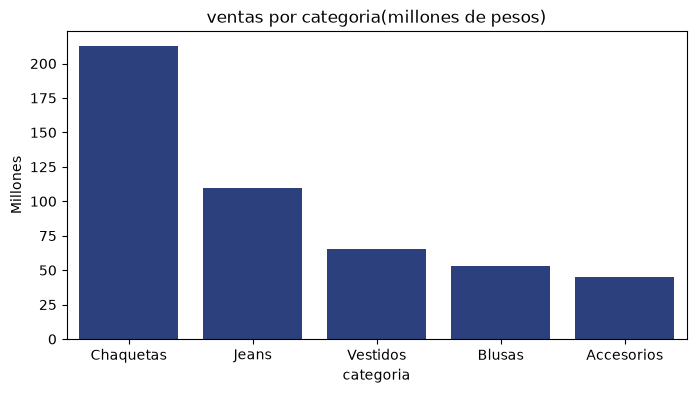

In [ ]:
## creación columna importe ventas
df_full["importe_ventas"]= df_full["cantidad"]*df_full["precio_venta"]*(1-df_full["descuento"])

### agrupamos por categoria
ventas_categoria= (df_full.groupby("categoria")["importe_ventas"].sum().sort_values(ascending=False) / 1_000_000 ) #en millones

## grafico de barras
plt.figure(figsize=(8,4))  #tamaño estandar
sns.barplot(x=ventas_categoria.index, y=ventas_categoria.values, color="#1E3A8A") #index= titulo, values= valores
plt.title("ventas por categoria(millones de pesos)")
plt.xlabel("categoria")
plt.ylabel("Millones")
plt.show()   #para mostrar 


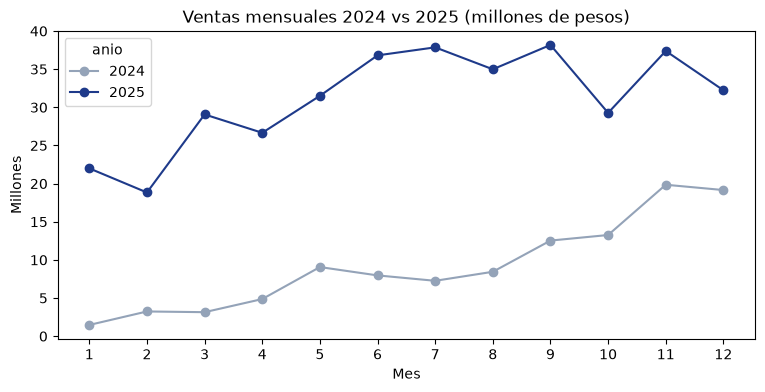

In [59]:
# Total por año y mes, con los años como columnas
mensual = df_full.pivot_table(index="mes", columns="anio", values="importe_ventas", aggfunc="sum") / 1_000_000

mensual.plot(marker="o", figsize=(9, 4), color=["#94A3B8", "#1E3A8A"])
plt.title("Ventas mensuales 2024 vs 2025 (millones de pesos)")
plt.xlabel("Mes")
plt.ylabel("Millones")
plt.xticks(range(1, 13))
plt.show()

In [60]:
##cual es la diferencia entre los dos codigos?
#1. Uso de pivot_table + gráfico de líneas (segundo código) :
# cuando se quiere ver la evolución en el tiempo y comparar dos o más categorías lado a lado (en este caso, comparar el comportamiento de cada mes entre 2024 y 2025).
# uso de group by+ grafico de barras->cuando se quiere hacer un ranking o comparación simple de una sola variable numérica dividida por una única categoría.


## Tabla RFM

In [ ]:
# Una  fila por cliente con cada variable de comportamiento 
fecha_final = df_full["fecha"].max()
tabla_cliente= df_full.groupby("id_cliente").agg(  #Se pone .agg porque crearé varias columnas
    recencia= ("fecha", lambda s: (fecha_final-s.max()) .days), #dias sin compra
    frecuencia=("id_venta","count"),
    monto =("importe_ventas", "sum"),
    ticket=("importe_ventas","mean"),
    descuento=("descuento","mean"), #mean me muestra promedio
    categorias=("categoria","nunique")  #nunique me muestra cantidad unica
)

tabla_cliente.head()



,recencia,frecuencia,monto,ticket,descuento,categorias
id_cliente,,,,,,
1,3,8,1409100.0,176137.500000,0.087500,5
2,32,6,1198100.0,199683.333333,0.083333,3
3,1,25,5585200.0,223408.000000,0.048000,5
4,107,13,3454200.0,265707.692308,0.084615,5
5,8,17,2685400.0,157964.705882,0.088235,5


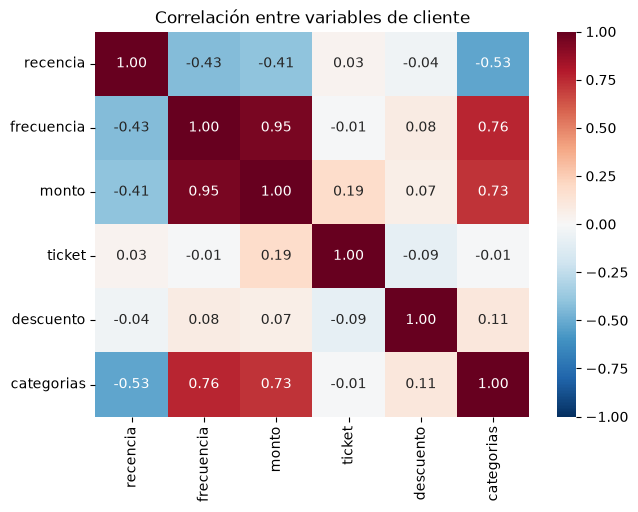

In [62]:
# 2. Matriz de correlación y mapa de calor
correlacion = tabla_cliente.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables de cliente")
plt.show()

In [ ]:
# entre mas cercano a 1 es que las dos crecen, correlación positiva .correlación positiva significa que cuando una variable aumenta, la otra tiende a aumentar también.
# Una correlación negativa significa que cuando una variable aumenta, la otra tiende a disminuir.
# si esta muy cercano a cero es que no hay correlación 
# siempre tiene diagonal de unos

#ejemplo: frecuencia y monto. entre mas veces compro, mas gasto
#frecuencia y categoria:los clientes que compran mas seguido, compran tambien mas categorias
#categoria y recencia: quien compra en mas categoria vuelve en menos tiempo
#el ticket no se relaciona con ninguna de forma significativa, igual que el descuento: no estan concentrados en los clientes mas fieles


## Fase de modelamiento
 la idea es enseñarle al modelo con los clientes del pasado que volvieron a comprar, entonces vamos a crear la variable objetivo con una fecha de corte

In [ ]:
# se debe de crear una variable por cliente que me dira si el cliente me compra o no me compra en los proximos 3 meses
# es un modelo de clasificacion , es un modelo sueprvisado porque depende de su pasado. su modelo base es la regresion logistica
# la variable objetivo es categorica, tiene dos categorias (0 y 1, me compra o no)
# 1- preparar BD
# 2- ingenieria de caracteristica
# 3- TRAIN and test : division de la bd
# 4- evalua y entrega el resultado al modelo df, prod, despliega en una API

In [ ]:
def construir_dataset(df, fecha_corte, dias_ventana=92):
    fecha_corte=pd.Timestamp(fecha_corte)
    fin_ventana= fecha_corte +pd.Timedelta(days=dias_ventana)

    historia= df[df["fecha"]<= fecha_corte]
    futuro= df[(df["fecha"]> fecha_corte) & (df["fecha"] <= fin_ventana)]

    X = historia.groupby("id_cliente").agg(
    recencia=("fecha", lambda s: (fecha_corte - s.max()).days), 
    frecuencia=("id_venta", "count"),
    monto=("importe_ventas", "sum"),
    ticket=("importe_ventas", "mean"),
    descuento=("descuento", "mean"),
    categorias=("categoria","nunique"),
    antiguedad =("fecha", lambda s :(fecha_corte - s.min()).days)
)

    y= X.index.isin(futuro["id_cliente"]).astype(int)  #esto me convertira en unos y ceros
    return X, pd.Series(y, index= X.index, name = "compra")

In [88]:
X_train, y_train = construir_dataset(df_full, "2025-06-30")  # aprende: ¿compró entre julio y septiembre?
X_test, y_test = construir_dataset(df_full, "2025-09-30")    # se evalúa: ¿compró entre octubre y diciembre?

In [89]:
print(f"Entrenamiento: {len(X_train)} clientes | {y_train.mean():.1%} volvió")
print(f"Prueba:       {len(X_test)} clientes | {y_test.mean():.1%} volvió")

Entrenamiento: 318 clientes | 59.1% volvió
Prueba:       368 clientes | 55.2% volvió
